# ACA 1 · Computación en la Nube
## Ingesta, vectorización y almacenamiento vectorial en clúster cloud para un sistema RAG
### Pilar 2 — Educación: asistente de consulta académica, normatividad institucional y permanencia estudiantil

**Corporación Unificada Nacional de Educación Superior (CUN)** · Escuela de Ingeniería · Especialización en Inteligencia Artificial<br>
**Docente:** Hamilton Rivera Flor<br>
**Integrantes:** Bonny Darhyll Brayan Galindo Santos · Camilo José Rodríguez Ayubi · Andrés Alberto López Herrera<br>
**Fecha:** noviembre de 2026

---

**Objetivo general.** Diseñar e implementar la arquitectura cloud de ingesta, fragmentación (*chunking*), generación de embeddings y almacenamiento semántico en una base de datos vectorial gestionada (Qdrant Cloud), integrando los metadatos de un dataset estructurado (UCI *Predict Students' Dropout and Academic Success*) con un corpus de documentos normativos colombianos sobre permanencia y bienestar estudiantil.

**Pregunta orientadora.** ¿Cómo estructurar una canalización de datos no estructurados en la nube, con una base vectorial *serverless* y modelos de embeddings, que permita indexar y recuperar semánticamente información especializada con alta precisión, costo cero y baja latencia?

**Situación problema.** En Colombia cerca de la mitad de quienes ingresan a un programa universitario no lo terminan (MEN, 2015). Las reglas que podrían ayudar a un estudiante en riesgo —reintegros, cancelación de asignaturas, apoyos de bienestar, estrategias de permanencia— están dispersas en reglamentos y guías de cientos de páginas que casi nadie consulta a tiempo. Este proyecto construye la capa de recuperación de un asistente que responde esas preguntas con el fragmento exacto de la norma y, además, con evidencia cuantitativa sobre los factores que más pesan en la deserción.

### Arquitectura implementada

```
 ┌──────────────────────── FUENTES ─────────────────────────┐
 │  Dataset estructurado (UCI, 4.424 estudiantes, CSV)      │
 │  Corpus no estructurado (3 PDF: CUN + MEN 2015 + MEN 2016)│
 └───────────────┬──────────────────────────┬───────────────┘
                 │ Paso 2: ingesta           │
        ┌────────▼────────┐        ┌────────▼─────────┐
        │ Capa SQL        │        │ Extracción y     │
        │ (SQLite)        │        │ limpieza (pypdf) │
        │ tasas de        │──────► │ + metadatos      │
        │ deserción por   │ fichas │ contextuales     │
        │ factor          │ y tags └────────┬─────────┘
        └─────────────────┘                 │ Paso 3: chunking
                                   ┌────────▼─────────┐
                                   │ RecursiveCharacter│
                                   │ TextSplitter      │
                                   └────────┬─────────┘
                                            │ Paso 4: embeddings
                      ┌─────────────────────┴───────────────────┐
              ┌───────▼────────┐                       ┌────────▼────────┐
              │ Gemini API     │                       │ multilingual-E5 │
              │ gemini-embed-2 │ 768 d (principal)     │ small · 384 d   │ (línea base)
              └───────┬────────┘                       └────────┬────────┘
                      └──────────── batch upsert ───────────────┘
                                            │ Paso 1: Qdrant Cloud (free tier 1 GB)
                                   ┌────────▼─────────┐
                                   │ Colección con 2  │
                                   │ vectores nombrados│
                                   │ · métrica coseno │
                                   │ · índices payload│
                                   └────────┬─────────┘
                                            │ Paso 5: búsqueda semántica Top-k
                                   ┌────────▼─────────┐
                                   │ Contexto para el │
                                   │ LLM del RAG      │
                                   └──────────────────┘
```

| Componente | Elección | Por qué |
|---|---|---|
| Base vectorial | **Qdrant Cloud** (free tier, 1 GB permanente) | Vectores nombrados en una sola colección, filtros por metadatos indexados, dashboard web, cliente Python maduro |
| Capa SQL | **SQLite** (estándar SQL, migrable a Supabase/PostgreSQL) | Consultas de agregación sobre el dataset para generar metadatos contextuales |
| Embeddings principal | **Gemini `gemini-embedding-2`** vía Google AI Studio, 768 dimensiones | Multilingüe, ventana de 8.192 tokens, consulta asimétrica (equivalente a `RETRIEVAL_QUERY`) |
| Embeddings línea base | **`intfloat/multilingual-e5-small`** (HuggingFace), 384 dimensiones | Abierto, corre local sin cuota, buen desempeño en español |
| Chunking | `RecursiveCharacterTextSplitter` (LangChain) | Respeta la jerarquía *capítulo → artículo → párrafo → oración* |
| Entorno | Google Colab (CPU o GPU T4) + repositorio GitHub | Reproducible y gratuito |

## 0. Preparación del entorno

Instalación de dependencias. En Colab tarda alrededor de un minuto. Se recomienda **Entorno de ejecución → Cambiar tipo → GPU T4** para acelerar el modelo E5, aunque todo funciona también en CPU.

In [17]:
%pip install -q "qdrant-client>=1.12" "google-genai>=1.30" "sentence-transformers>=3.0" \
                "langchain-text-splitters>=0.3" "pypdf>=5.0" python-dotenv pandas matplotlib tqdm requests

In [18]:
import os, re, io, json, time, uuid, pickle, hashlib, sqlite3, unicodedata, zipfile, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
SEMILLA = 42
np.random.seed(SEMILLA)

# Carpetas de trabajo
BASE = Path.cwd()
DIR_CORPUS, DIR_DATOS, DIR_CACHE, DIR_RES = (BASE / d for d in ("corpus", "datos", "cache", "resultados"))
for d in (DIR_CORPUS, DIR_DATOS, DIR_CACHE, DIR_RES):
    d.mkdir(exist_ok=True)
print("Directorio de trabajo:", BASE)

Directorio de trabajo: /content


## 1. Gestión segura de credenciales (`.env`)

Ninguna llave está escrita en este cuaderno. Se leen de un archivo `.env` (que **no** se sube al repositorio, ver `.gitignore`) con esta estructura:

```
QDRANT_URL=https://xxxxxxxx.us-east4-0.gcp.cloud.qdrant.io:6333
QDRANT_API_KEY=...
GOOGLE_API_KEY=...
GEMINI_EMBED_MODEL=gemini-embedding-2
```

En Colab hay dos formas de suministrarlo: subir el `.env` al panel de archivos o registrar las mismas variables en **🔑 Secretos** (barra lateral). La celda intenta ambas y solo muestra si cada variable quedó cargada, nunca su valor.

In [19]:
from dotenv import load_dotenv
load_dotenv(BASE / ".env", override=False)

VARIABLES = ["QDRANT_URL", "QDRANT_API_KEY", "GOOGLE_API_KEY", "GEMINI_EMBED_MODEL"]
try:  # Respaldo: Secretos de Google Colab
    from google.colab import userdata
    for v in VARIABLES:
        if not os.getenv(v):
            try:
                os.environ[v] = userdata.get(v)
            except Exception:
                pass
except ImportError:
    pass

# Limpia espacios o caracteres invisibles que se cuelan al copiar y pegar las llaves
os.environ.update({v: os.environ[v].strip() for v in VARIABLES if os.environ.get(v)})
os.environ.setdefault("GEMINI_EMBED_MODEL", "gemini-embedding-2")

def _enmascarar(valor):
    return "no definida ❌" if not valor else f"cargada ✅ ({len(valor)} caracteres)"

for v in VARIABLES:
    print(f"{v:<20} {_enmascarar(os.getenv(v))}")

QDRANT_URL = os.getenv("QDRANT_URL")
QDRANT_API_KEY = os.getenv("QDRANT_API_KEY")
GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
GEMINI_EMBED_MODEL = os.getenv("GEMINI_EMBED_MODEL", "gemini-embedding-2")
assert QDRANT_URL and GOOGLE_API_KEY, "Faltan credenciales: revise el archivo .env o los Secretos de Colab."

QDRANT_URL           cargada ✅ (81 caracteres)
QDRANT_API_KEY       cargada ✅ (176 caracteres)
GOOGLE_API_KEY       cargada ✅ (39 caracteres)
GEMINI_EMBED_MODEL   cargada ✅ (18 caracteres)


## 2. Parámetros del experimento

Todos los valores que afectan los resultados están reunidos aquí para que cualquier corrida sea reproducible.

In [20]:
COLECCION        = "aca1_educacion_permanencia"
RECREAR_COLECCION = True          # True: borra y vuelve a crear la colección (idempotente)

# Embeddings
DIM_GEMINI   = 768                # gemini-embedding-2 admite 128–3072; 768 equilibra precisión y almacenamiento
MODELO_E5    = "intfloat/multilingual-e5-small"
DIM_E5       = 384

# Chunking: tamaños candidatos (caracteres) y solapamiento relativo
TAMANOS_CANDIDATOS = [500, 1000, 1500]
SOLAPAMIENTO_REL   = 0.15

# Cuotas de la capa gratuita de Gemini (ajustables según el panel de AI Studio)
GEMINI_MAX_TOKENS_REQ = 7000      # límite duro del modelo: 8.192 tokens por petición
GEMINI_MAX_ITEMS_REQ  = 32
GEMINI_PAUSA_SEG      = 0.8       # pausa entre peticiones para no saturar RPM/TPM

LOTE_UPSERT = 64
TOP_K = 5

## 3. PASO 1 — Aprovisionamiento de la base de datos vectorial (Qdrant Cloud)

**Despliegue.** En [cloud.qdrant.io](https://cloud.qdrant.io) se creó el clúster `aca1-cun` en el plan *Free* (Qdrant v1.20, 1 GiB de RAM, 4 GiB de disco, 0,5 vCPU, sin vencimiento) en AWS `us-east-1` (N. Virginia). En la pestaña *API Keys* del clúster se generó una llave con permisos de lectura y escritura; la URL y la llave viven solo en el `.env`.

**Decisiones de diseño de la colección:**

- **Dos vectores nombrados** (`gemini` de 768 d y `e5` de 384 d) en la misma colección. Cada fragmento se guarda una sola vez con su payload y puede consultarse con cualquiera de los dos modelos, lo que permite compararlos sin duplicar datos.
- **Distancia coseno.** Ambos modelos se entrenaron con objetivos contrastivos sobre similitud coseno; además, los vectores se normalizan, así que coseno y producto punto producen el mismo orden.
- **Índices de payload** sobre `fuente_id`, `tipo_documento`, `factores_riesgo` y `pagina` para filtrar sin recorrer la colección completa (Qdrant Cloud los exige en filtros cuando el *strict mode* está activo).

In [21]:
from qdrant_client import QdrantClient, models

if QDRANT_URL == ":memory:":                     # modo local solo para pruebas sin nube
    qdrant = QdrantClient(location=":memory:")
else:
    qdrant = QdrantClient(url=QDRANT_URL, api_key=QDRANT_API_KEY, timeout=60)

t0 = time.perf_counter()
existentes = [c.name for c in qdrant.get_collections().collections]
print(f"Conexión OK con Qdrant ({(time.perf_counter()-t0)*1000:.0f} ms). Colecciones existentes: {existentes}")

if RECREAR_COLECCION and qdrant.collection_exists(COLECCION):
    qdrant.delete_collection(COLECCION)

if not qdrant.collection_exists(COLECCION):
    qdrant.create_collection(
        collection_name=COLECCION,
        vectors_config={
            "gemini": models.VectorParams(size=DIM_GEMINI, distance=models.Distance.COSINE),
            "e5":     models.VectorParams(size=DIM_E5,     distance=models.Distance.COSINE),
        },
        hnsw_config=models.HnswConfigDiff(m=16, ef_construct=100),
    )
    for campo, tipo in [("fuente_id", models.PayloadSchemaType.KEYWORD),
                        ("tipo_documento", models.PayloadSchemaType.KEYWORD),
                        ("factores_riesgo", models.PayloadSchemaType.KEYWORD),
                        ("pagina", models.PayloadSchemaType.INTEGER)]:
        qdrant.create_payload_index(COLECCION, field_name=campo, field_schema=tipo)

info = qdrant.get_collection(COLECCION)
print("Estado:", info.status)
for nombre, p in info.config.params.vectors.items():
    print(f"  vector '{nombre}': {p.size} dimensiones · distancia {p.distance}")
print("Índices de payload:", list(info.payload_schema.keys()))

Conexión OK con Qdrant (668 ms). Colecciones existentes: ['aca1_educacion_permanencia']
Estado: green
  vector 'e5': 384 dimensiones · distancia Cosine
  vector 'gemini': 768 dimensiones · distancia Cosine
Índices de payload: ['pagina', 'factores_riesgo', 'fuente_id', 'tipo_documento']


## 4. PASO 2 — Documentos e ingesta

### 4.1 Dataset base estructurado y capa SQL

Se usa **UCI *Predict Students' Dropout and Academic Success*** (Realinho et al., 2021): 4.424 estudiantes de pregrado de un instituto politécnico portugués, 36 variables (demográficas, socioeconómicas, académicas del primer año y macroeconómicas) y la variable objetivo `Target` ∈ {Dropout, Enrolled, Graduate}.

El dataset no se vectoriza fila por fila: 4.424 registros numéricos convertidos en texto aportarían ruido, no significado. Se carga en una tabla SQL y con consultas de agregación se calculan las tasas de deserción por factor. Esos resultados cumplen dos funciones:

1. Se redactan como **fichas analíticas** (documentos cortos en lenguaje natural) que también se indexan, para que el asistente pueda responder con evidencia cuantitativa.
2. Se adjuntan como **metadatos contextuales** a los fragmentos de los PDF que hablan del mismo factor (por ejemplo, un artículo sobre pagos de matrícula queda etiquetado con la tasa de deserción observada en estudiantes con deudas).

In [22]:
URL_UCI = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
URL_RESPALDO = ("https://raw.githubusercontent.com/hamzaezzine/Predict-students-dropout-and-academic-success-"
                "using-machine-learning-algorithms/main/dataset.csv")
CABECERAS = {"User-Agent": "Mozilla/5.0 (ACA1-CUN; fines academicos)"}

def cargar_dataset():
    try:
        r = requests.get(URL_UCI, headers=CABECERAS, timeout=60); r.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            nombre = [n for n in z.namelist() if n.endswith(".csv")][0]
            df = pd.read_csv(z.open(nombre), sep=";", encoding="utf-8-sig")
        origen = "UCI Machine Learning Repository"
    except Exception as e:
        print(f"UCI no disponible ({type(e).__name__}); se usa la copia pública en GitHub.")
        df = pd.read_csv(URL_RESPALDO, encoding="utf-8-sig")
        origen = "Copia en GitHub del dataset UCI"
    df.columns = [c.strip() for c in df.columns]
    return df, origen

df, ORIGEN_DATASET = cargar_dataset()
df.to_csv(DIR_DATOS / "students_dropout.csv", index=False)
print(f"Origen: {ORIGEN_DATASET} · {df.shape[0]} filas × {df.shape[1]} columnas")
display(df["Target"].value_counts().rename_axis("Target").to_frame("estudiantes"))

Origen: UCI Machine Learning Repository · 4424 filas × 37 columnas


,estudiantes
Target,
Graduate,2209
Dropout,1421
Enrolled,794


In [23]:
# Nombres de los programas: UCI usa códigos (33, 171, …); la versión de Kaggle/GitHub usa 1–17 en el mismo orden.
PROGRAMAS = ["Tecnologías de producción de biocombustibles", "Diseño de animación y multimedia",
             "Servicio social (nocturno)", "Agronomía", "Diseño de comunicación", "Enfermería veterinaria",
             "Ingeniería informática", "Equinocultura", "Administración", "Servicio social", "Turismo",
             "Enfermería", "Higiene oral", "Gestión de publicidad y marketing", "Periodismo y comunicación",
             "Educación básica", "Administración (nocturno)"]
CODIGOS_UCI = [33, 171, 8014, 9003, 9070, 9085, 9119, 9130, 9147, 9238, 9254, 9500, 9556, 9670, 9773, 9853, 9991]
mapa = dict(zip(CODIGOS_UCI, PROGRAMAS)) if df["Course"].max() > 17 else dict(zip(range(1, 18), PROGRAMAS))
df["programa"] = df["Course"].map(mapa)

# Variables derivadas para la capa SQL
df["tasa_aprob_sem1"] = np.where(df["Curricular units 1st sem (enrolled)"] > 0,
                                 df["Curricular units 1st sem (approved)"] / df["Curricular units 1st sem (enrolled)"], np.nan)
df["banda_aprob_sem1"] = pd.cut(df["tasa_aprob_sem1"], [-0.01, 0.0, 0.5, 0.99, 1.0],
                                labels=["0 % aprobado", "1–50 %", "51–99 %", "100 % aprobado"]).astype(object).fillna("sin asignaturas inscritas")
df["banda_edad"] = pd.cut(df["Age at enrollment"], [0, 20, 24, 34, 120],
                          labels=["17–20 años", "21–24 años", "25–34 años", "35 años o más"]).astype(object)

# Capa SQL: base relacional local (mismo SQL estándar que PostgreSQL/Supabase)
con = sqlite3.connect(DIR_DATOS / "estudiantes.db")
df.rename(columns=lambda c: re.sub(r"[^0-9a-zA-Z_]+", "_", c).strip("_").lower()).to_sql(
    "estudiantes", con, if_exists="replace", index=False)
print(pd.read_sql("SELECT COUNT(*) AS registros FROM estudiantes", con))

   registros
0       4424


In [24]:
def tasas_por(columna, etiquetas=None):
    q = f'''
        SELECT {columna} AS valor,
               COUNT(*)                                             AS n,
               ROUND(100.0*SUM(target='Dropout')/COUNT(*), 1)       AS pct_desercion,
               ROUND(100.0*SUM(target='Graduate')/COUNT(*), 1)      AS pct_graduacion,
               ROUND(100.0*SUM(target='Enrolled')/COUNT(*), 1)      AS pct_matriculado
        FROM estudiantes GROUP BY {columna} ORDER BY pct_desercion DESC'''
    t = pd.read_sql(q, con)
    if etiquetas:
        t["valor"] = t["valor"].map(etiquetas).fillna(t["valor"])
    return t

SI_NO = {0: "No", 1: "Sí"}
# factor -> (columna SQL, etiquetas, categoría de riesgo, descripción en español)
FACTORES_SQL = {
    "Deudor con la institución":       ("debtor", SI_NO, "financiero", "tener deudas pendientes con la institución"),
    "Matrícula al día":                ("tuition_fees_up_to_date", SI_NO, "financiero", "tener el pago de la matrícula al día"),
    "Becado":                          ("scholarship_holder", SI_NO, "financiero", "contar con beca"),
    "Aprobación de asignaturas sem. 1": ("banda_aprob_sem1", None, "academico", "el porcentaje de asignaturas aprobadas en el primer semestre"),
    "Edad al ingresar":                ("banda_edad", None, "socioeconomico_personal", "la edad al momento de ingresar"),
    "Jornada":                         ("daytime_evening_attendance", {0: "Nocturna", 1: "Diurna"}, "socioeconomico_personal", "la jornada de estudio"),
    "Sexo":                            ("gender", {0: "Mujer", 1: "Hombre"}, "socioeconomico_personal", "el sexo del estudiante"),
    "Desplazado":                      ("displaced", SI_NO, "socioeconomico_personal", "vivir desplazado de su lugar de origen"),
    "Necesidades educativas especiales": ("educational_special_needs", SI_NO, "socioeconomico_personal", "tener necesidades educativas especiales"),
    "Programa académico":              ("programa", None, "academico", "el programa académico"),
}
TABLAS = {f: tasas_por(c, e) for f, (c, e, _, _) in FACTORES_SQL.items()}
GLOBAL = tasas_por("'Todos'")
print(f"Deserción global: {GLOBAL.pct_desercion[0]} %")
for f in ["Deudor con la institución", "Matrícula al día", "Becado", "Aprobación de asignaturas sem. 1"]:
    display(Markdown(f"**{f}**")); display(TABLAS[f])

Deserción global: 32.1 %


**Deudor con la institución**

,valor,n,pct_desercion,pct_graduacion,pct_matriculado
0,Sí,503,62.0,20.1,17.9
1,No,3921,28.3,53.8,18.0


**Matrícula al día**

,valor,n,pct_desercion,pct_graduacion,pct_matriculado
0,No,528,86.6,5.5,8.0
1,Sí,3896,24.7,56.0,19.3


**Becado**

,valor,n,pct_desercion,pct_graduacion,pct_matriculado
0,No,3325,38.7,41.3,20.0
1,Sí,1099,12.2,76.0,11.8


**Aprobación de asignaturas sem. 1**

,valor,n,pct_desercion,pct_graduacion,pct_matriculado
0,0 % aprobado,538,91.6,0.4,8.0
1,1–50 %,423,70.4,3.5,26.0
2,sin asignaturas inscritas,180,42.8,41.7,15.6
3,51–99 %,1555,25.9,46.4,27.7
4,100 % aprobado,1728,8.7,80.7,10.5


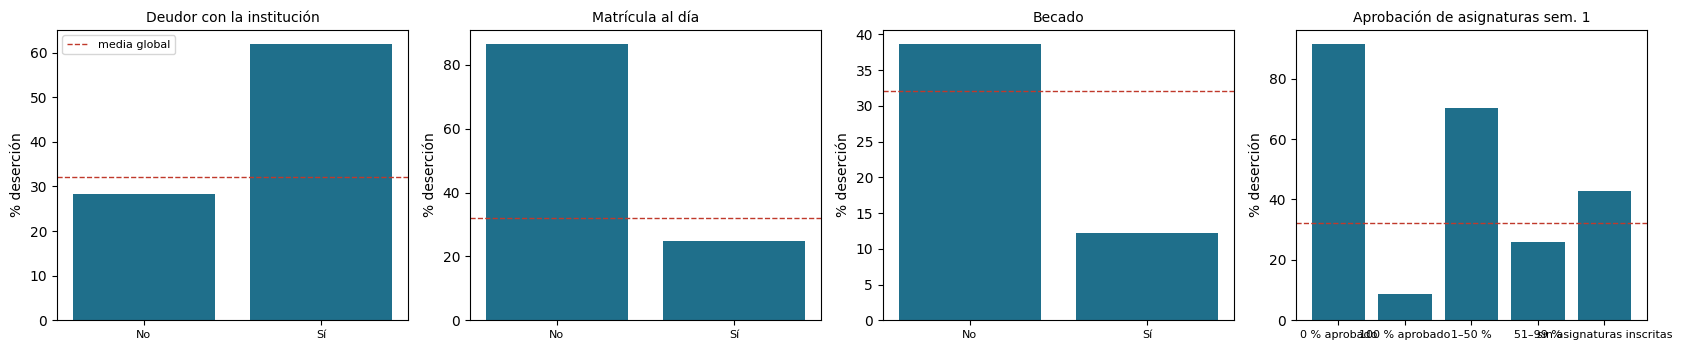

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, f in zip(axes, ["Deudor con la institución", "Matrícula al día", "Becado", "Aprobación de asignaturas sem. 1"]):
    t = TABLAS[f].sort_values("valor")
    ax.bar([str(v) for v in t["valor"]], t["pct_desercion"], color="#1f6f8b")
    ax.axhline(GLOBAL.pct_desercion[0], ls="--", c="#c0392b", lw=1, label="media global")
    ax.set_title(f, fontsize=10); ax.set_ylabel("% deserción"); ax.tick_params(axis="x", labelsize=8)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(DIR_RES / "fig_desercion_factores.png", dpi=200); plt.show()

### 4.2 Fichas analíticas generadas desde SQL

Cada factor se convierte en un texto breve en español con las cifras de la consulta. Así el conocimiento cuantitativo del dataset entra a la base vectorial como un tipo de documento más (`ficha_dataset`).

In [26]:
def fmt(x):
    return f"{x:.1f}".replace(".", ",")

FICHAS = []
for factor, (col, etq, categoria, descripcion) in FACTORES_SQL.items():
    t = TABLAS[factor]
    filas = "; ".join(f"{r.valor}: {fmt(r.pct_desercion)} % de deserción, {fmt(r.pct_graduacion)} % de graduación "
                      f"(n = {r.n})" for r in t.itertuples())
    mayor, menor = t.iloc[0], t.iloc[-1]
    texto = (f"Ficha analítica del dataset UCI Predict Students' Dropout and Academic Success ({len(df)} estudiantes de "
             f"educación superior). Factor analizado: {factor.lower()}, es decir, {descripcion}. "
             f"La deserción global de la cohorte es {fmt(GLOBAL.pct_desercion[0])} %. Resultados por grupo: {filas}. "
             f"El grupo con mayor deserción es «{mayor.valor}» ({fmt(mayor.pct_desercion)} %) y el de menor deserción es "
             f"«{menor.valor}» ({fmt(menor.pct_desercion)} %), una diferencia de "
             f"{fmt(mayor.pct_desercion - menor.pct_desercion)} puntos porcentuales. "
             f"Este factor se relaciona con riesgo de tipo {categoria.replace('_', ' ')} en la permanencia estudiantil.")
    FICHAS.append({"factor": factor, "categoria": categoria, "variable": col, "texto": texto,
                   "evidencia": f"{factor}: «{mayor.valor}» {fmt(mayor.pct_desercion)} % vs «{menor.valor}» "
                                f"{fmt(menor.pct_desercion)} % de deserción"})

# Evidencia más fuerte por categoría de riesgo (se usará como metadato de los fragmentos de los PDF)
EVIDENCIA_CATEGORIA = {}
for f in FICHAS:
    t = TABLAS[f["factor"]]
    brecha = t.pct_desercion.max() - t.pct_desercion.min()
    if brecha > EVIDENCIA_CATEGORIA.get(f["categoria"], (0, ""))[0]:
        EVIDENCIA_CATEGORIA[f["categoria"]] = (brecha, f["evidencia"])
EVIDENCIA_CATEGORIA = {k: v[1] for k, v in EVIDENCIA_CATEGORIA.items()}

print(f"{len(FICHAS)} fichas generadas. Ejemplo:\n")
print(FICHAS[0]["texto"])
print("\nEvidencia por categoría:", json.dumps(EVIDENCIA_CATEGORIA, ensure_ascii=False, indent=1))

10 fichas generadas. Ejemplo:

Ficha analítica del dataset UCI Predict Students' Dropout and Academic Success (4424 estudiantes de educación superior). Factor analizado: deudor con la institución, es decir, tener deudas pendientes con la institución. La deserción global de la cohorte es 32,1 %. Resultados por grupo: Sí: 62,0 % de deserción, 20,1 % de graduación (n = 503); No: 28,3 % de deserción, 53,8 % de graduación (n = 3921). El grupo con mayor deserción es «Sí» (62,0 %) y el de menor deserción es «No» (28,3 %), una diferencia de 33,7 puntos porcentuales. Este factor se relaciona con riesgo de tipo financiero en la permanencia estudiantil.

Evidencia por categoría: {
 "financiero": "Matrícula al día: «No» 86,6 % vs «Sí» 24,7 % de deserción",
 "academico": "Aprobación de asignaturas sem. 1: «0 % aprobado» 91,6 % vs «100 % aprobado» 8,7 % de deserción",
 "socioeconomico_personal": "Edad al ingresar: «25–34 años» 56,5 % vs «17–20 años» 21,2 % de deserción"
}


### 4.3 Corpus documental complementario (PDF)

| ID | Documento | Entidad | Año | Aporta al asistente |
|---|---|---|---|---|
| `reglamento_cun` | Reglamento Estudiantil — Acuerdo 002 de 2011 del Consejo Directivo | CUN | 2011 | Reglas de matrícula, retiros, reintegros, transferencias, evaluación, grados y derechos del estudiante |
| `guia_permanencia_men` | Guía para la implementación del modelo de gestión de permanencia y graduación estudiantil en IES | Ministerio de Educación Nacional | 2015 | Marco conceptual de la deserción, ruta de implementación y caja de herramientas con estrategias |
| `bienestar_men` | Lineamientos de política de bienestar para instituciones de educación superior | Ministerio de Educación Nacional | 2016 | Principios, dimensiones y componentes del bienestar institucional |

Los tres documentos se complementan: el reglamento responde *qué puedo hacer yo como estudiante*, la guía del MEN responde *qué debe hacer la institución para retenerme* y los lineamientos de bienestar cubren el acompañamiento integral. Juntos cubren las categorías de riesgo que el dataset permite medir.

> El notebook intenta primero la URL oficial y, si no responde, descarga la copia guardada en la carpeta `corpus/` del repositorio (mismo nombre de archivo que en el portal oficial). Si ambas fallan, basta con subir el PDF a la carpeta `corpus/` con el nombre indicado en la columna `archivo` y volver a ejecutar la celda. Si su institución publicó una versión más reciente del reglamento, puede reemplazar el archivo manteniendo el nombre.

In [27]:
CORPUS = [
    {"fuente_id": "reglamento_cun", "tipo_documento": "reglamento", "anio": 2011,
     "titulo": "Reglamento Estudiantil CUN (Acuerdo 002 de 2011 del Consejo Directivo)",
     "entidad": "Corporación Unificada Nacional de Educación Superior (CUN)",
     "archivo": "reglamento_estudiantil_cun.pdf",
     "url": "https://cdigital.cun.edu.co/pluginfile.php/364670/course/summary/Reglamento%20Estudiantil.pdf"},
    {"fuente_id": "guia_permanencia_men", "tipo_documento": "guia_permanencia", "anio": 2015,
     "titulo": "Guía para la implementación del modelo de gestión de permanencia y graduación estudiantil en IES",
     "entidad": "Ministerio de Educación Nacional de Colombia",
     "archivo": "men_guia_permanencia_2015.pdf",
     "url": "https://www.mineducacion.gov.co/1780/articles-356272_recurso.pdf"},
    {"fuente_id": "bienestar_men", "tipo_documento": "politica_bienestar", "anio": 2016,
     "titulo": "Lineamientos de política de bienestar para instituciones de educación superior",
     "entidad": "Ministerio de Educación Nacional de Colombia",
     "archivo": "men_lineamientos_bienestar_2016.pdf",
     "url": "https://www.mineducacion.gov.co/1780/articles-360314_recurso.pdf"},
]

# Copia de respaldo en el repositorio del proyecto: algunos portales oficiales no responden
# a conexiones desde fuera de Colombia (es el caso de Colab, que corre en EE. UU.).
REPO_CORPUS = "https://raw.githubusercontent.com/BonnyGalindo77/aca1-rag-educacion-qdrant/main/corpus/"

def descargar_pdf(doc):
    destino = DIR_CORPUS / doc["archivo"]
    if destino.exists() and destino.read_bytes()[:4] == b"%PDF":
        return "en caché"
    for origen, url in (("fuente oficial", doc["url"]), ("copia en GitHub", REPO_CORPUS + doc["url"].rsplit("/", 1)[-1])):
        try:
            r = requests.get(url, headers=CABECERAS, timeout=(15, 120)); r.raise_for_status()
            if r.content[:4] != b"%PDF":
                raise ValueError("la respuesta no es un PDF")
            destino.write_bytes(r.content)
            return f"descargado ({origen})"
        except Exception as e:
            ultimo_error = type(e).__name__
    return f"FALLÓ ({ultimo_error}) → súbalo manualmente a corpus/{doc['archivo']}"

for doc in CORPUS:
    estado = descargar_pdf(doc)
    tam = (DIR_CORPUS / doc["archivo"]).stat().st_size / 1e6 if (DIR_CORPUS / doc["archivo"]).exists() else 0
    print(f"{doc['fuente_id']:<22} {estado:<34} {tam:5.2f} MB")

reglamento_cun         en caché                            0.38 MB
guia_permanencia_men   descargado (copia en GitHub)        7.50 MB
bienestar_men          descargado (copia en GitHub)        0.70 MB


### 4.4 Extracción y limpieza del texto

Los PDF institucionales traen ruido que degrada los embeddings: encabezados y pies repetidos en cada página, números de página sueltos, palabras partidas con guion al final de línea y espacios irregulares. La limpieza:

1. Extrae el texto página por página con `pypdf` y conserva el número de página como metadato.
2. Elimina las líneas que se repiten en más del 40 % de las páginas (encabezados y pies institucionales).
3. Une palabras cortadas por guion, normaliza espacios y descarta las páginas casi vacías (portadas, páginas en blanco).

In [28]:
from pypdf import PdfReader

def limpiar_paginas(paginas):
    lineas_por_pag = [set(l.strip() for l in p.splitlines() if l.strip()) for p in paginas]
    conteo = Counter(l for s in lineas_por_pag for l in s)
    umbral = max(3, 0.4 * len(paginas))
    repetidas = {l for l, c in conteo.items() if c >= umbral and len(l) < 120}
    limpias = []
    for p in paginas:
        lineas = [l for l in p.splitlines() if l.strip() and l.strip() not in repetidas
                  and not re.fullmatch(r"\s*(p[áa]g(ina)?\.?\s*)?\d{1,3}\s*", l, flags=re.I)]
        t = "\n".join(lineas)
        t = re.sub(r"(\w)-\n(\w)", r"\1\2", t)          # palabras partidas con guion
        t = re.sub(r"[ \t ]+", " ", t)
        t = re.sub(r"\n{3,}", "\n\n", t)
        limpias.append(t.strip())
    return limpias, len(repetidas)

DOCUMENTOS = []
for doc in CORPUS:
    ruta = DIR_CORPUS / doc["archivo"]
    if not ruta.exists():
        print(f"⚠️  Falta {ruta.name}; se omite."); continue
    lector = PdfReader(str(ruta))
    crudas = [(p.extract_text() or "") for p in lector.pages]
    limpias, n_rep = limpiar_paginas(crudas)
    paginas = [(i + 1, t) for i, t in enumerate(limpias) if len(t) >= 80]
    DOCUMENTOS.append({**doc, "paginas": paginas, "n_paginas_pdf": len(crudas)})
    print(f"{doc['fuente_id']:<22} {len(crudas):>4} páginas · {len(paginas):>4} con texto útil · "
          f"{sum(len(t) for _, t in paginas):>8,} caracteres · {n_rep} líneas repetidas eliminadas")

assert DOCUMENTOS, "No hay documentos en el corpus."

reglamento_cun           45 páginas ·   45 con texto útil ·   99,030 caracteres · 1 líneas repetidas eliminadas
guia_permanencia_men    227 páginas ·  225 con texto útil ·  399,150 caracteres · 0 líneas repetidas eliminadas
bienestar_men            55 páginas ·   50 con texto útil ·  112,495 caracteres · 0 líneas repetidas eliminadas


### 4.5 Asociación con los metadatos del dataset

Cada fragmento de los PDF se etiqueta con las **categorías de riesgo** que menciona (financiero, académico, socioeconómico/personal, bienestar, normativo) y con las **variables del dataset** relacionadas. Cuando la categoría tiene evidencia en el dataset, el fragmento lleva además la cifra correspondiente. Así un artículo sobre pago de matrícula se recupera junto con el dato de que los estudiantes deudores desertan mucho más que el resto, y los filtros por `factores_riesgo` permiten cruzar norma y evidencia.

In [29]:
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFD", s.lower()) if unicodedata.category(c) != "Mn")

CATEGORIAS = {
    "financiero": (["deuda", "pago", "matricula", "financ", "beca", "credito educativo", "paz y salvo", "costo",
                    "apoyo economico", "subsidio", "icetex", "derechos pecuniarios", "descuento"],
                   ["debtor", "tuition_fees_up_to_date", "scholarship_holder"]),
    "academico": (["asignatura", "calificacion", "nota", "evaluacion", "rendimiento", "reprob", "tutoria",
                   "creditos academicos", "promedio", "nivelacion", "monitoria", "validacion", "habilitacion"],
                  ["curricular_units_1st_sem_approved", "curricular_units_1st_sem_grade", "course"]),
    "socioeconomico_personal": (["familia", "edad", "trabaj", "discapacidad", "vulnerab", "desplaz", "genero",
                                 "etnic", "necesidades educativas", "condicion socioeconomica", "madre", "padre"],
                                ["age_at_enrollment", "displaced", "educational_special_needs", "gender", "marital_status"]),
    "bienestar_institucional": (["bienestar", "salud mental", "psicolog", "acompanamiento", "consejeria",
                                 "orientacion", "deporte", "cultur", "convivencia", "desarrollo humano"], []),
    "normativo": (["articulo", "acuerdo", "reglamento", "sancion", "derecho", "deber", "reintegro",
                   "transferencia", "homologa", "retiro", "cancelacion", "aplazamiento"], []),
}

def etiquetar(texto):
    t = sin_tildes(texto)
    cats = [c for c, (claves, _) in CATEGORIAS.items() if sum(t.count(k) for k in claves) >= 2]
    variables = sorted({v for c in cats for v in CATEGORIAS[c][1]})
    evidencia = [EVIDENCIA_CATEGORIA[c] for c in cats if c in EVIDENCIA_CATEGORIA]
    return cats, variables, evidencia

print(etiquetar("ARTÍCULO 15. El estudiante que no esté a paz y salvo por concepto de pago de matrícula y "
                "derechos pecuniarios no podrá inscribir asignaturas."))

(['financiero', 'normativo'], ['debtor', 'scholarship_holder', 'tuition_fees_up_to_date'], ['Matrícula al día: «No» 86,6 % vs «Sí» 24,7 % de deserción'])


## 5. PASO 3 — Pipeline de chunking

### 5.1 Estrategia

Se usa `RecursiveCharacterTextSplitter` con separadores ordenados según la estructura de los documentos normativos: primero intenta cortar en `CAPÍTULO`, luego en `ARTÍCULO`, después en párrafos, líneas, oraciones y, solo como último recurso, en palabras. De esta forma un artículo corto queda completo en un fragmento y uno largo se divide por párrafos sin partir oraciones.

El fragmento conserva su posición (`start_index`) dentro del documento; con ella se recupera la página exacta para citarla.

### 5.2 Justificación del tamaño

El tamaño del fragmento es un compromiso:

- **Muy pequeño (≈500 caracteres):** el fragmento pierde el contexto que le da sentido. Un parágrafo queda separado del artículo al que pertenece y el vector representa una idea incompleta.
- **Muy grande (≈1.500 caracteres):** mezcla varios temas en un solo vector, diluye la señal semántica y se acerca al límite de 512 tokens de E5 (en español, ≈1.500 caracteres equivalen a 400–450 tokens del tokenizador XLM-R). Además, el LLM del RAG recibe más texto irrelevante por cada resultado.
- **Intermedio (≈1.000 caracteres, ≈250 tokens):** coincide con la longitud típica de un artículo del reglamento o de una estrategia de la caja de herramientas del MEN.

El solapamiento de 15 % evita que una idea que cae justo en el borde se pierda en ambos fragmentos.

La decisión no se toma solo por criterio: la siguiente sección mide las tres opciones con un conjunto de consultas de validación y el modelo E5 (local, sin consumir cuota de la nube) antes de indexar en Qdrant.

In [30]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

SEPARADORES = ["\nCAPÍTULO", "\nCapítulo", "\nARTÍCULO", "\nArtículo", "\n\n", "\n", ". ", "; ", ", ", " ", ""]

def fragmentar(documentos, fichas, tamano, solap_rel=SOLAPAMIENTO_REL):
    splitter = RecursiveCharacterTextSplitter(chunk_size=tamano, chunk_overlap=int(tamano * solap_rel),
                                              separators=SEPARADORES, add_start_index=True, strip_whitespace=True)
    chunks = []
    for doc in documentos:
        texto, inicios, pos = "", [], 0
        for num, t in doc["paginas"]:
            inicios.append((pos, num)); texto += t + "\n\n"; pos = len(texto)
        for i, d in enumerate(splitter.create_documents([texto])):
            ini = d.metadata["start_index"]
            pagina = max((n for p, n in inicios if p <= ini), default=1)
            cats, variables, evid = etiquetar(d.page_content)
            chunks.append({"fuente_id": doc["fuente_id"], "tipo_documento": doc["tipo_documento"],
                           "titulo": doc["titulo"], "entidad": doc["entidad"], "anio": doc["anio"],
                           "url": doc["url"], "pagina": pagina, "chunk_idx": i, "texto": d.page_content,
                           "factores_riesgo": cats, "variables_dataset": variables, "evidencia_dataset": evid})
    for i, f in enumerate(fichas):     # las fichas son cortas: cada una es un fragmento completo
        chunks.append({"fuente_id": "dataset_uci", "tipo_documento": "ficha_dataset",
                       "titulo": f"Ficha analítica: {f['factor']}", "entidad": "UCI Machine Learning Repository",
                       "anio": 2021, "url": "https://doi.org/10.24432/C5MC89", "pagina": 0, "chunk_idx": i,
                       "texto": f["texto"], "factores_riesgo": [f["categoria"]], "variables_dataset": [f["variable"]],
                       "evidencia_dataset": [f["evidencia"]]})
    for c in chunks:
        c["n_caracteres"] = len(c["texto"])
        c["n_tokens_aprox"] = round(len(c["texto"]) / 4)
        c["chunk_size"] = tamano
    return chunks

CANDIDATOS = {t: fragmentar(DOCUMENTOS, FICHAS, t) for t in TAMANOS_CANDIDATOS}
resumen = pd.DataFrame([{"chunk_size": t, "fragmentos": len(c),
                         "media_caracteres": np.mean([x["n_caracteres"] for x in c]),
                         "p95_caracteres": np.percentile([x["n_caracteres"] for x in c], 95),
                         "media_tokens_aprox": np.mean([x["n_tokens_aprox"] for x in c])}
                        for t, c in CANDIDATOS.items()]).round(0)
display(resumen)

,chunk_size,fragmentos,media_caracteres,p95_caracteres,media_tokens_aprox
0,500,1571,421.0,495.0,105.0
1,1000,854,786.0,993.0,196.0
2,1500,610,1090.0,1494.0,272.0


## 6. PASO 4 — Vectorización (embeddings)

### 6.1 Modelos

**Principal — Gemini `gemini-embedding-2` (Google AI Studio).** Modelo multilingüe con ventana de 8.192 tokens. Se pide una salida de **768 dimensiones** (aprendizaje Matryoshka: el modelo concentra la información en las primeras dimensiones, de modo que truncar a 768 pierde muy poca calidad y reduce 4 veces el almacenamiento frente a 3.072).

> **Sobre `RETRIEVAL_QUERY`.** En `gemini-embedding-001` la tarea se declara con el parámetro `task_type` (`RETRIEVAL_DOCUMENT` para indexar, `RETRIEVAL_QUERY` para consultar). En `gemini-embedding-2` Google retiró ese parámetro y lo reemplazó por instrucciones en el propio texto: `title: … | text: …` para documentos y `task: search result | query: …` para consultas, que es el equivalente oficial de `RETRIEVAL_QUERY`. El código soporta ambos modelos: si en el `.env` se define `GEMINI_EMBED_MODEL=gemini-embedding-001`, se usa `task_type="RETRIEVAL_QUERY"` literalmente.

**Línea base — `intfloat/multilingual-e5-small` (HuggingFace).** 118 M de parámetros, 384 dimensiones, corre local en Colab sin consumir cuota. E5 también es asimétrico: exige los prefijos `passage:` y `query:`.

### 6.2 Control de cuota (capa gratuita)

- Las peticiones a Gemini se arman por lotes que no superan ~7.000 tokens estimados ni 32 textos (el límite del modelo es 8.192 tokens por petición).
- Pausa fija entre lotes y reintentos con espera exponencial ante errores `429 RESOURCE_EXHAUSTED`.
- **Caché en disco** por hash del texto: si el notebook se vuelve a ejecutar, no se paga dos veces el mismo embedding.

In [31]:
from google import genai
from google.genai import types

cliente_gemini = genai.Client(api_key=GOOGLE_API_KEY)
ES_GEMINI_2 = GEMINI_EMBED_MODEL.startswith("gemini-embedding-2")

class CacheEmbeddings:
    def __init__(self, ruta):
        self.ruta = ruta
        self.datos = pickle.loads(ruta.read_bytes()) if ruta.exists() else {}
    def clave(self, texto, modo):
        return hashlib.sha1(f"{GEMINI_EMBED_MODEL}|{DIM_GEMINI}|{modo}|{texto}".encode()).hexdigest()
    def guardar(self):
        self.ruta.write_bytes(pickle.dumps(self.datos))

cache_gemini = CacheEmbeddings(DIR_CACHE / "embeddings_gemini.pkl")
USO_GEMINI = {"peticiones": 0, "tokens_aprox": 0, "reintentos": 0}

def _preparar(texto, modo, titulo=None):
    if not ES_GEMINI_2:
        return texto
    if modo == "consulta":
        return f"task: search result | query: {texto}"
    return f"title: {titulo or 'none'} | text: {texto}"

def _llamar_gemini(lote, modo):
    if ES_GEMINI_2:
        contenidos = [types.Content(parts=[types.Part.from_text(text=t)]) for t in lote]
        config = types.EmbedContentConfig(output_dimensionality=DIM_GEMINI)
    else:
        contenidos = lote
        config = types.EmbedContentConfig(output_dimensionality=DIM_GEMINI,
                                          task_type="RETRIEVAL_QUERY" if modo == "consulta" else "RETRIEVAL_DOCUMENT")
    for intento in range(7):
        try:
            r = cliente_gemini.models.embed_content(model=GEMINI_EMBED_MODEL, contents=contenidos, config=config)
            USO_GEMINI["peticiones"] += 1
            return [e.values for e in r.embeddings]
        except Exception as e:
            msg = str(e)
            if any(x in msg for x in ("429", "RESOURCE_EXHAUSTED", "503", "UNAVAILABLE", "500")) and intento < 6:
                espera = min(60, 2 ** intento * 2); USO_GEMINI["reintentos"] += 1
                print(f"  cuota/servicio ocupado, reintento en {espera}s…"); time.sleep(espera)
            else:
                raise

def embeber_gemini(textos, modo="documento", titulos=None, progreso=True):
    titulos = titulos or [None] * len(textos)
    preparados = [_preparar(t, modo, ti) for t, ti in zip(textos, titulos)]
    claves = [cache_gemini.clave(p, modo) for p in preparados]
    pendientes = [i for i, k in enumerate(claves) if k not in cache_gemini.datos]
    lotes, actual, tok = [], [], 0          # lotes por presupuesto de tokens
    for i in pendientes:
        t = max(1, len(preparados[i]) // 4)
        if actual and (tok + t > GEMINI_MAX_TOKENS_REQ or len(actual) >= GEMINI_MAX_ITEMS_REQ):
            lotes.append(actual); actual, tok = [], 0
        actual.append(i); tok += t
    if actual: lotes.append(actual)
    for n, lote in enumerate(tqdm(lotes, desc=f"Gemini ({modo})", disable=not progreso or not lotes)):
        if n: time.sleep(GEMINI_PAUSA_SEG)          # pausa solo entre lotes consecutivos
        vecs = _llamar_gemini([preparados[i] for i in lote], modo)
        for i, v in zip(lote, vecs):
            v = np.asarray(v, dtype=np.float32)
            cache_gemini.datos[claves[i]] = v / np.linalg.norm(v)
        USO_GEMINI["tokens_aprox"] += sum(len(preparados[i]) // 4 for i in lote)
    if lotes: cache_gemini.guardar()
    return np.vstack([cache_gemini.datos[k] for k in claves])

prueba = embeber_gemini(["¿Cuál es el plazo para solicitar reintegro?"], modo="consulta", progreso=False)
print(f"Modelo: {GEMINI_EMBED_MODEL} · dimensión {prueba.shape[1]} · norma {np.linalg.norm(prueba):.3f}")

Modelo: gemini-embedding-2 · dimensión 768 · norma 1.000


In [32]:
from sentence_transformers import SentenceTransformer
import torch

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
modelo_e5 = SentenceTransformer(MODELO_E5, device=dispositivo)

def embeber_e5(textos, modo="documento", progreso=True):
    prefijo = "query: " if modo == "consulta" else "passage: "
    return modelo_e5.encode([prefijo + t for t in textos], batch_size=32, normalize_embeddings=True,
                            show_progress_bar=progreso, convert_to_numpy=True).astype(np.float32)

print(f"E5 cargado en {dispositivo} · dimensión {embeber_e5(['prueba'], progreso=False).shape[1]} "
      f"· longitud máxima {modelo_e5.max_seq_length} tokens")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

E5 cargado en cuda · dimensión 384 · longitud máxima 512 tokens


### 6.3 Conjunto de validación y selección del tamaño de chunk

Se definieron consultas en lenguaje natural, redactadas como las haría un estudiante, cada una con la(s) fuente(s) donde debe encontrarse la respuesta. Las mismas consultas sirven luego para evaluar la búsqueda en Qdrant (Paso 5).

Métricas:

- **Hit@k:** proporción de consultas con al menos un fragmento de la fuente correcta entre los *k* primeros.
- **MRR (*Mean Reciprocal Rank*):** promedio de 1/posición del primer acierto; premia que el acierto aparezca arriba.

In [33]:
VALIDACION = [
    ("¿Qué pasa si pierdo la misma asignatura por tercera vez?", {"reglamento_cun"}),
    ("¿Cuánto tiempo tengo para pedir reintegro después de retirarme de la universidad?", {"reglamento_cun"}),
    ("¿Qué necesito tener a paz y salvo para poder graduarme?", {"reglamento_cun"}),
    ("¿Cómo se hace una transferencia desde otra institución y qué materias me homologan?", {"reglamento_cun"}),
    ("¿Qué estrategias recomienda el Ministerio para apoyar a estudiantes con dificultades económicas?", {"guia_permanencia_men"}),
    ("¿Cuáles son los pasos para implementar un modelo de gestión de la permanencia en una institución?", {"guia_permanencia_men"}),
    ("¿Para qué sirve el sistema SPADIES en el seguimiento de la deserción?", {"guia_permanencia_men"}),
    ("¿Cómo pueden las universidades trabajar con los colegios para reducir la deserción en primer semestre?", {"guia_permanencia_men"}),
    ("¿Cuáles son las dimensiones del bienestar en la educación superior?", {"bienestar_men"}),
    ("¿Qué responsabilidades tienen los actores en la implementación de la política de bienestar?", {"bienestar_men"}),
    ("¿Los estudiantes con deudas con la institución abandonan más sus estudios?", {"dataset_uci", "guia_permanencia_men"}),
    ("¿Tener beca reduce la probabilidad de desertar?", {"dataset_uci", "guia_permanencia_men"}),
    ("¿Qué relación hay entre aprobar pocas materias en el primer semestre y la deserción?", {"dataset_uci", "guia_permanencia_men"}),
    ("¿En qué programas académicos se presenta la mayor deserción?", {"dataset_uci"}),
]
FUERA_DE_DOMINIO = ["¿Cuál es la receta tradicional del ajiaco santafereño?",
                    "¿Quién ganó el mundial de fútbol de 2014?"]

def evaluar(matriz_docs, chunks, consultas_emb, k=TOP_K):
    sims = consultas_emb @ matriz_docs.T
    filas = []
    for (pregunta, relevantes), s in zip(VALIDACION, sims):
        orden = np.argsort(-s)[:k]
        fuentes = [chunks[i]["fuente_id"] for i in orden]
        rango = next((r + 1 for r, f in enumerate(fuentes) if f in relevantes), None)
        filas.append({"consulta": pregunta, "rango_primer_acierto": rango, "top1_fuente": fuentes[0],
                      "score_top1": float(s[orden[0]]), "margen_top1_top2": float(s[orden[0]] - s[orden[1]])})
    d = pd.DataFrame(filas)
    metricas = {f"Hit@{n}": float((d.rango_primer_acierto <= n).mean()) for n in (1, 3, k)}
    metricas["MRR"] = float(d.rango_primer_acierto.apply(lambda r: 1 / r if pd.notna(r) else 0).mean())
    metricas["score_top1_medio"] = float(d.score_top1.mean())
    return metricas, d

consultas_e5 = embeber_e5([q for q, _ in VALIDACION], modo="consulta", progreso=False)
EXPERIMENTO = []
for tam, chunks in CANDIDATOS.items():
    m, _ = evaluar(embeber_e5([c["texto"] for c in chunks], progreso=False), chunks, consultas_e5)
    EXPERIMENTO.append({"chunk_size": tam, "fragmentos": len(chunks), **m})
EXPERIMENTO = pd.DataFrame(EXPERIMENTO).round(3)
display(EXPERIMENTO)

# Regla de selección: mayor MRR; en empate (±0,01) se prefiere 1.000 caracteres por las razones de la sección 5.2
mejor = EXPERIMENTO.MRR.max()
empatados = EXPERIMENTO[EXPERIMENTO.MRR >= mejor - 0.01].chunk_size.tolist()
CHUNK_SIZE = 1000 if 1000 in empatados else int(EXPERIMENTO.loc[EXPERIMENTO.MRR.idxmax(), "chunk_size"])
CHUNKS = CANDIDATOS[CHUNK_SIZE]
print(f"\nTamaño seleccionado: {CHUNK_SIZE} caracteres (solapamiento {int(CHUNK_SIZE*SOLAPAMIENTO_REL)}) → "
      f"{len(CHUNKS)} fragmentos")

,chunk_size,fragmentos,Hit@1,Hit@3,Hit@5,MRR,score_top1_medio
0,500,1571,0.929,0.929,1.0,0.943,0.891
1,1000,854,0.929,0.929,1.0,0.946,0.894
2,1500,610,0.929,1.000,1.0,0.964,0.891



Tamaño seleccionado: 1500 caracteres (solapamiento 225) → 610 fragmentos


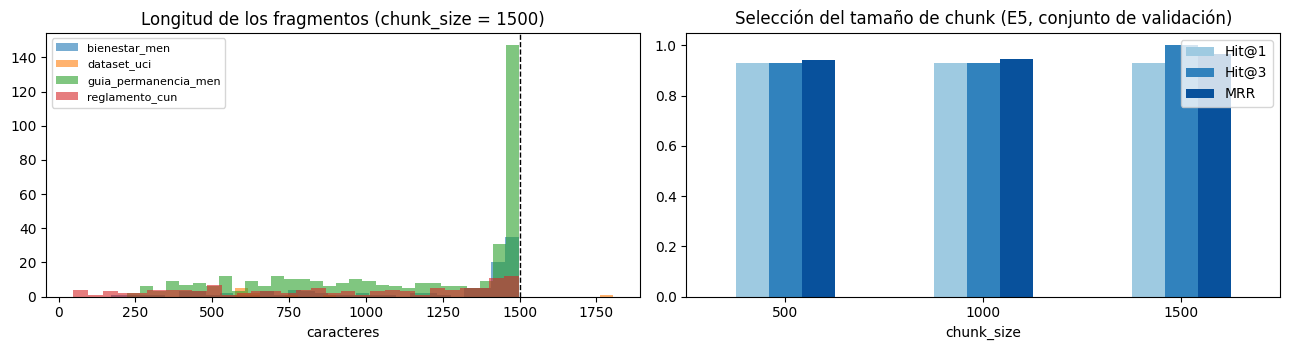

,fuente_id,tipo_documento,fragmentos
0,bienestar_men,politica_bienestar,104
1,dataset_uci,ficha_dataset,10
2,guia_permanencia_men,guia_permanencia,383
3,reglamento_cun,reglamento,113


Ejemplo de fragmento:
 {
 "fuente_id": "reglamento_cun",
 "tipo_documento": "reglamento",
 "titulo": "Reglamento Estudiantil CUN (Acuerdo 002 de 2011 del Consejo Directivo)",
 "entidad": "Corporación Unificada Nacional de Educación Superior (CUN)",
 "anio": 2011,
 "url": "https://cdigital.cun.edu.co/pluginfile.php/364670/course/summary/Reglamento%20Estudiantil.pdf",
 "pagina": 2,
 "chunk_idx": 5,
 "factores_riesgo": [
  "normativo"
 ],
 "variables_dataset": [],
 "evidencia_dataset": [],
 "n_caracteres": 347,
 "n_tokens_aprox": 87,
 "chunk_size": 1500
}
Artículo 5. REQUISITOS (MODIFICADO POR EL ACUERDO No 0 02 DE 2016 DEL 
CONSEJO DIRECTIVO): Son requisitos para el ingreso a los programas que oferta la 
Corporación, además de los generales que señale la ley, y de los específicos que fije la 
Institución para cada programa académico, los siguientes: 
1. Para los programas Técnicos Profesionales:


In [34]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for fuente, grupo in pd.DataFrame(CHUNKS).groupby("fuente_id"):
    ax[0].hist(grupo.n_caracteres, bins=30, alpha=.6, label=fuente)
ax[0].axvline(CHUNK_SIZE, c="k", ls="--", lw=1); ax[0].set_title(f"Longitud de los fragmentos (chunk_size = {CHUNK_SIZE})")
ax[0].set_xlabel("caracteres"); ax[0].legend(fontsize=8)
EXPERIMENTO.set_index("chunk_size")[["Hit@1", "Hit@3", "MRR"]].plot.bar(ax=ax[1], rot=0, color=["#9ecae1", "#3182bd", "#08519c"])
ax[1].set_ylim(0, 1.05); ax[1].set_title("Selección del tamaño de chunk (E5, conjunto de validación)")
plt.tight_layout(); plt.savefig(DIR_RES / "fig_chunking.png", dpi=200); plt.show()

conteo = pd.DataFrame(CHUNKS).groupby(["fuente_id", "tipo_documento"]).size().rename("fragmentos").reset_index()
display(conteo)
print("Ejemplo de fragmento:\n", json.dumps({k: v for k, v in CHUNKS[5].items() if k != "texto"}, ensure_ascii=False, indent=1))
print(CHUNKS[5]["texto"][:600])

### 6.4 Vectorización del corpus final

Se estima primero el consumo para verificar que cabe en la capa gratuita y luego se generan los dos juegos de vectores.

In [35]:
textos = [c["texto"] for c in CHUNKS]
titulos = [c["titulo"] for c in CHUNKS]
tokens_est = sum(len(_preparar(t, "documento", ti)) // 4 for t, ti in zip(textos, titulos))
print(f"Fragmentos: {len(textos)} · tokens estimados para Gemini: {tokens_est:,} · "
      f"peticiones estimadas: ~{int(np.ceil(tokens_est / GEMINI_MAX_TOKENS_REQ))}")

t0 = time.perf_counter(); VEC_GEMINI = embeber_gemini(textos, modo="documento", titulos=titulos)
t_gemini = time.perf_counter() - t0
t0 = time.perf_counter(); VEC_E5 = embeber_e5(textos, modo="documento")
t_e5 = time.perf_counter() - t0
print(f"Gemini: {VEC_GEMINI.shape} en {t_gemini:.1f}s · E5: {VEC_E5.shape} en {t_e5:.1f}s · uso Gemini: {USO_GEMINI}")

Fragmentos: 610 · tokens estimados para Gemini: 181,650 · peticiones estimadas: ~26


Gemini (documento):   0%|          | 0/27 [00:00<?, ?it/s]

  cuota/servicio ocupado, reintento en 2s…
  cuota/servicio ocupado, reintento en 4s…
  cuota/servicio ocupado, reintento en 8s…
  cuota/servicio ocupado, reintento en 16s…
  cuota/servicio ocupado, reintento en 32s…
  cuota/servicio ocupado, reintento en 2s…
  cuota/servicio ocupado, reintento en 4s…
  cuota/servicio ocupado, reintento en 8s…
  cuota/servicio ocupado, reintento en 16s…
  cuota/servicio ocupado, reintento en 32s…
  cuota/servicio ocupado, reintento en 2s…
  cuota/servicio ocupado, reintento en 2s…
  cuota/servicio ocupado, reintento en 4s…
  cuota/servicio ocupado, reintento en 8s…
  cuota/servicio ocupado, reintento en 16s…
  cuota/servicio ocupado, reintento en 2s…
  cuota/servicio ocupado, reintento en 4s…
  cuota/servicio ocupado, reintento en 8s…
  cuota/servicio ocupado, reintento en 16s…
  cuota/servicio ocupado, reintento en 32s…
  cuota/servicio ocupado, reintento en 2s…
  cuota/servicio ocupado, reintento en 4s…
  cuota/servicio ocupado, reintento en 8s…
  cu

Batches:   0%|          | 0/20 [00:00<?, ?it/s]

Gemini: (610, 768) en 374.9s · E5: (610, 384) en 4.0s · uso Gemini: {'peticiones': 28, 'tokens_aprox': 181668, 'reintentos': 29}


### 6.5 Carga masiva a Qdrant Cloud (*batch upsert*)

- **IDs deterministas** (UUID v5 a partir de fuente + índice + tamaño de chunk): si la carga se repite, los puntos se sobrescriben en lugar de duplicarse.
- Lotes de 64 puntos con `wait=True`, para confirmar cada escritura antes de enviar la siguiente.
- Antes de cargar se estima el espacio ocupado frente al límite de 1 GB del plan gratuito.

In [36]:
bytes_vectores = len(CHUNKS) * (DIM_GEMINI + DIM_E5) * 4
bytes_payload = sum(len(json.dumps(c, ensure_ascii=False).encode()) for c in CHUNKS)
estimado_mb = (bytes_vectores * 1.5 + bytes_payload) / 1e6          # 1,5× por el grafo HNSW y metadatos internos
print(f"Espacio estimado: {estimado_mb:.1f} MB ≈ {estimado_mb/1024*100:.2f} % del free tier (1 GB)")

def id_punto(c):
    return str(uuid.uuid5(uuid.NAMESPACE_URL, f"{c['fuente_id']}|{c['chunk_idx']}|{c['chunk_size']}"))

puntos = [models.PointStruct(id=id_punto(c),
                             vector={"gemini": VEC_GEMINI[i].tolist(), "e5": VEC_E5[i].tolist()},
                             payload={**c, "pilar": "educacion", "modelo_principal": GEMINI_EMBED_MODEL})
          for i, c in enumerate(CHUNKS)]

t0 = time.perf_counter()
for i in tqdm(range(0, len(puntos), LOTE_UPSERT), desc="Upsert a Qdrant"):
    qdrant.upsert(collection_name=COLECCION, points=puntos[i:i + LOTE_UPSERT], wait=True)
t_upsert = time.perf_counter() - t0

total = qdrant.count(COLECCION, exact=True).count
print(f"Puntos en la colección: {total} (esperados {len(puntos)}) · tiempo de carga {t_upsert:.1f}s")
assert total == len(puntos)

Espacio estimado: 5.3 MB ≈ 0.52 % del free tier (1 GB)


Upsert a Qdrant:   0%|          | 0/10 [00:00<?, ?it/s]

Puntos en la colección: 610 (esperados 610) · tiempo de carga 4.7s


## 7. PASO 5 — Búsqueda semántica

La función `buscar`:

1. Recibe la pregunta del usuario.
2. La vectoriza con Gemini en modo **consulta** (`task: search result | query: …`, equivalente a `RETRIEVAL_QUERY`) o con E5 (`query: …`).
3. Ejecuta la búsqueda por similitud coseno en Qdrant Cloud sobre el vector nombrado correspondiente, con filtros opcionales por metadatos.
4. Devuelve los **Top-k** fragmentos con su puntaje, fuente y página, más la latencia de cada etapa.

In [37]:
def buscar(pregunta, k=TOP_K, modelo="gemini", filtro=None, mostrar=True):
    t0 = time.perf_counter()
    vec = (embeber_gemini([pregunta], modo="consulta", progreso=False) if modelo == "gemini"
           else embeber_e5([pregunta], modo="consulta", progreso=False))[0]
    t1 = time.perf_counter()
    condiciones = None
    if filtro:
        condiciones = models.Filter(must=[
            models.FieldCondition(key=c, match=models.MatchAny(any=v) if isinstance(v, list) else models.MatchValue(value=v))
            for c, v in filtro.items()])
    res = qdrant.query_points(collection_name=COLECCION, query=vec.tolist(), using=modelo, limit=k,
                              query_filter=condiciones, with_payload=True).points
    t2 = time.perf_counter()
    tabla = pd.DataFrame([{"rank": i + 1, "score_coseno": round(p.score, 4), "fuente": p.payload["fuente_id"],
                           "pagina": p.payload["pagina"], "factores": ", ".join(p.payload["factores_riesgo"]),
                           "fragmento": p.payload["texto"][:230].replace("\n", " ") + "…"} for i, p in enumerate(res)])
    lat = {"embedding_ms": round((t1 - t0) * 1000, 1), "busqueda_ms": round((t2 - t1) * 1000, 1)}
    if mostrar:
        display(Markdown(f"**Consulta:** {pregunta}  \n*Modelo:* `{modelo}` · *filtro:* `{filtro}` · "
                         f"*latencia:* embedding {lat['embedding_ms']} ms + Qdrant {lat['busqueda_ms']} ms"))
        display(tabla)
    return res, tabla, lat

_ = buscar("¿Qué pasa si pierdo la misma asignatura por tercera vez?")

**Consulta:** ¿Qué pasa si pierdo la misma asignatura por tercera vez?  
*Modelo:* `gemini` · *filtro:* `None` · *latencia:* embedding 429.8 ms + Qdrant 225.7 ms

,rank,score_coseno,fuente,pagina,factores,fragmento
0,1,0.7977,reglamento_cun,26,"academico, normativo","Artículo 58. PERDIDA REITERADA DE ASIGNATURAS: El estudiante que deba cursar una asignatura por tercera vez o más, sólo podrá cursarla ..."
1,2,0.6842,reglamento_cun,38,"financiero, normativo",Artículo 87. SANCIONES PRINCIPALES (MODIFICADO POR EL ART. 2 DEL ACUERDO No 004 DE 2017 DEL CONSEJO DIRECTIVO): Los destinatarios de es...
2,3,0.6795,reglamento_cun,24,"academico, normativo",Artículo 53. C RITERIOS APROBATORIOS: Una asignatura será aprobada si se obtiene la nota de tres punto cero (3.0) en adelante. Para ef...
3,4,0.6787,reglamento_cun,2,"financiero, normativo",Artículo 3. DE LA PÉRDIDA DE LA CALIDAD DE ESTUDIANTE: La calidad de estudiante se pierde en los siguientes eventos: a) Cuando no se r...
4,5,0.6705,reglamento_cun,25,"academico, normativo",Artículo 56. CORRECCIÓN DE NOTAS: (MODIFICADO ACUERDO No. 25 DE 2019 DEL CONSEJO DIRECTIVO) Cuando un estudiante considere que existe u...


**Consulta:** ¿Los estudiantes con deudas con la institución abandonan más sus estudios?  
*Modelo:* `gemini` · *filtro:* `None` · *latencia:* embedding 422.3 ms + Qdrant 221.8 ms

,rank,score_coseno,fuente,pagina,factores,fragmento
0,1,0.8319,dataset_uci,0,financiero,Ficha analítica del dataset UCI Predict Students' Dropout and Academic Success (4424 estudiantes de educación superior). Factor analizad...
1,2,0.7738,dataset_uci,0,financiero,Ficha analítica del dataset UCI Predict Students' Dropout and Academic Success (4424 estudiantes de educación superior). Factor analizad...
2,3,0.7649,guia_permanencia_men,166,financiero,"los estudiantes que no recibe ningún apoyo financiero, en el mismo semestre abandona sus estudios apenas el 28 % de los estudiantes qu..."
3,4,0.7538,dataset_uci,0,financiero,Ficha analítica del dataset UCI Predict Students' Dropout and Academic Success (4424 estudiantes de educación superior). Factor analizad...
4,5,0.7476,guia_permanencia_men,224,financiero,"4.1.1 NIVELES DE DESERCIÓN POR APOYO ACADÉMICO 4.2 APOYOS FINANCIEROS En cuanto a los apoyos brindados por las IES, aquellos estudiante..."


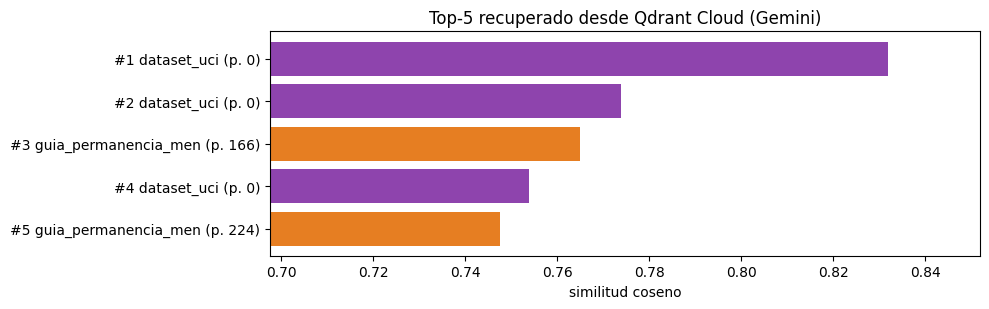


Texto completo del fragmento #1:
 Ficha analítica del dataset UCI Predict Students' Dropout and Academic Success (4424 estudiantes de educación superior). Factor analizado: deudor con la institución, es decir, tener deudas pendientes con la institución. La deserción global de la cohorte es 32,1 %. Resultados por grupo: Sí: 62,0 % de deserción, 20,1 % de graduación (n = 503); No: 28,3 % de deserción, 53,8 % de graduación (n = 3921). El grupo con mayor deserción es «Sí» (62,0 %) y el de menor deserción es «No» (28,3 %), una diferencia de 33,7 puntos porcentuales. Este factor se relaciona con riesgo de tipo financiero en la permanencia estudiantil.

Evidencia del dataset asociada: ['Deudor con la institución: «Sí» 62,0 % vs «No» 28,3 % de deserción']


In [38]:
# Visualización del Top-k para una consulta que cruza norma y evidencia del dataset
res, tabla, _ = buscar("¿Los estudiantes con deudas con la institución abandonan más sus estudios?", k=TOP_K)

fig, ax = plt.subplots(figsize=(10, 3.2))
etiquetas = [f"#{r.rank} {r.fuente} (p. {r.pagina})" for r in tabla.itertuples()]
colores = {"reglamento_cun": "#1f6f8b", "guia_permanencia_men": "#e67e22", "bienestar_men": "#27ae60", "dataset_uci": "#8e44ad"}
ax.barh(etiquetas[::-1], tabla.score_coseno[::-1], color=[colores.get(f, "gray") for f in tabla.fuente[::-1]])
ax.set_xlabel("similitud coseno"); ax.set_xlim(tabla.score_coseno.min() - 0.05, tabla.score_coseno.max() + 0.02)
ax.set_title("Top-5 recuperado desde Qdrant Cloud (Gemini)")
plt.tight_layout(); plt.savefig(DIR_RES / "fig_topk_ejemplo.png", dpi=200); plt.show()

print("\nTexto completo del fragmento #1:\n", res[0].payload["texto"])
print("\nEvidencia del dataset asociada:", res[0].payload["evidencia_dataset"])

### 7.1 Búsqueda con filtros por metadatos

Los índices de payload permiten restringir la búsqueda a un tipo de documento o a una categoría de riesgo, algo que en el RAG sirve para enrutar preguntas (por ejemplo, "solo normativa institucional").

In [39]:
_ = buscar("¿Puedo cancelar una materia y en qué plazo?", filtro={"tipo_documento": "reglamento"}, k=3)
_ = buscar("apoyos para estudiantes que no pueden pagar la matrícula", filtro={"factores_riesgo": ["financiero"]}, k=3)

**Consulta:** ¿Puedo cancelar una materia y en qué plazo?  
*Modelo:* `gemini` · *filtro:* `{'tipo_documento': 'reglamento'}` · *latencia:* embedding 389.7 ms + Qdrant 220.8 ms

,rank,score_coseno,fuente,pagina,factores,fragmento
0,1,0.7776,reglamento_cun,15,"academico, normativo",Artículo 35. DE LA CANCELACIÓN DE ASIGNATURAS Y EFECTOS DE LA CANCELACIÓN (MODIFICADO POR EL ACUERDO No 02 DE 20 16 DEL CONSEJO DIRECT...
1,2,0.7676,reglamento_cun,16,"academico, normativo","PARÁGRAFO PRIMERO: Las previsiones contenidas en el presente artículo se limitan a una cancelación por asignatura, sin que proceda una ..."
2,3,0.7467,reglamento_cun,7,"financiero, normativo",Artículo 16. RETIRO DEL ESTUDIANTE (MODIFICADO POR EL ACUERDO No 0 2 DE 2016 DEL CONSEJO DIRECTIVO): Es la cancelación voluntaria de la...


**Consulta:** apoyos para estudiantes que no pueden pagar la matrícula  
*Modelo:* `gemini` · *filtro:* `{'factores_riesgo': ['financiero']}` · *latencia:* embedding 705.7 ms + Qdrant 220.9 ms

,rank,score_coseno,fuente,pagina,factores,fragmento
0,1,0.7645,guia_permanencia_men,165,financiero,COMPONENTE 7 GESTIÓN DE RECURSOS HERRAMIENTA 32. SERVICIOS DE FINANCIAMIENTO ¿QUÉ ES? Es el conjunto de servicios que ofrece la institu...
1,2,0.7477,guia_permanencia_men,166,financiero,"los estudiantes que no recibe ningún apoyo financiero, en el mismo semestre abandona sus estudios apenas el 28 % de los estudiantes qu..."
2,3,0.7352,guia_permanencia_men,167,"financiero, academico, socioeconomico_personal","COMPONENTE 7 GESTIÓN DE RECURSOS ¿CÓMO SER MÁS EFICAZ? Establecer una unidad administrativa, con personal especializado que brinde ases..."


## 8. Validación cuantitativa de la recuperación

Se ejecutan las consultas de validación contra **Qdrant Cloud** con ambos modelos y se calculan Hit@k, MRR, puntaje coseno del Top-1, margen entre el primer y el segundo resultado y latencias. Como control negativo se incluyen preguntas fuera del dominio, cuyo puntaje debería quedar claramente por debajo.

In [40]:
def evaluar_en_qdrant(modelo):
    filas, lat = [], []
    for pregunta, relevantes in VALIDACION:
        res, _, l = buscar(pregunta, modelo=modelo, mostrar=False)
        fuentes = [p.payload["fuente_id"] for p in res]
        rango = next((r + 1 for r, f in enumerate(fuentes) if f in relevantes), None)
        filas.append({"modelo": modelo, "consulta": pregunta, "esperada": "/".join(sorted(relevantes)),
                      "top1_fuente": fuentes[0], "top1_pagina": res[0].payload["pagina"],
                      "rango_acierto": rango, "score_top1": res[0].score, "score_top5": res[-1].score,
                      "margen_top1_top2": res[0].score - res[1].score, "scores": [p.score for p in res]})
        lat.append(l)
    fuera = [buscar(q, modelo=modelo, mostrar=False)[0][0].score for q in FUERA_DE_DOMINIO]
    d = pd.DataFrame(filas)
    m = {"modelo": modelo,
         **{f"Hit@{n}": (d.rango_acierto <= n).mean() for n in (1, 3, 5)},
         "MRR": d.rango_acierto.apply(lambda r: 1 / r if pd.notna(r) else 0).mean(),
         "score_top1_medio": d.score_top1.mean(), "score_top1_min": d.score_top1.min(),
         "margen_medio": d.margen_top1_top2.mean(), "score_fuera_dominio": float(np.mean(fuera)),
         "lat_embedding_ms": np.median([x["embedding_ms"] for x in lat]),
         "lat_qdrant_ms": np.median([x["busqueda_ms"] for x in lat])}
    # Separación entre consultas del dominio y fuera de él, normalizada por la dispersión del modelo
    m["separacion_z"] = (m["score_top1_medio"] - m["score_fuera_dominio"]) / (d.score_top1.std() + 1e-9)
    return m, d

m_g, det_g = evaluar_en_qdrant("gemini")
m_e, det_e = evaluar_en_qdrant("e5")
METRICAS = pd.DataFrame([m_g, m_e]).set_index("modelo").round(3)
display(METRICAS)
display(det_g[["consulta", "esperada", "top1_fuente", "top1_pagina", "rango_acierto", "score_top1", "margen_top1_top2"]].round(3))

,Hit@1,Hit@3,Hit@5,MRR,score_top1_medio,score_top1_min,margen_medio,score_fuera_dominio,lat_embedding_ms,lat_qdrant_ms,separacion_z
modelo,,,,,,,,,,,
gemini,1.000,1.0,1.0,1.000,0.805,0.743,0.034,0.547,402.05,220.6,8.120
e5,0.929,1.0,1.0,0.964,0.891,0.864,0.015,0.767,14.10,219.7,8.048


,consulta,esperada,top1_fuente,top1_pagina,rango_acierto,score_top1,margen_top1_top2
0,¿Qué pasa si pierdo la misma asignatura por tercera vez?,reglamento_cun,reglamento_cun,26,1,0.798,0.113
1,¿Cuánto tiempo tengo para pedir reintegro después de retirarme de la universidad?,reglamento_cun,reglamento_cun,11,1,0.788,0.059
2,¿Qué necesito tener a paz y salvo para poder graduarme?,reglamento_cun,reglamento_cun,29,1,0.783,0.063
3,¿Cómo se hace una transferencia desde otra institución y qué materias me homologan?,reglamento_cun,reglamento_cun,11,1,0.768,0.003
4,¿Qué estrategias recomienda el Ministerio para apoyar a estudiantes con dificultades económicas?,guia_permanencia_men,guia_permanencia_men,167,1,0.766,0.003
5,¿Cuáles son los pasos para implementar un modelo de gestión de la permanencia en una institución?,guia_permanencia_men,guia_permanencia_men,70,1,0.852,0.007
6,¿Para qué sirve el sistema SPADIES en el seguimiento de la deserción?,guia_permanencia_men,guia_permanencia_men,51,1,0.842,0.014
7,¿Cómo pueden las universidades trabajar con los colegios para reducir la deserción en primer semestre?,guia_permanencia_men,guia_permanencia_men,218,1,0.743,0.007
8,¿Cuáles son las dimensiones del bienestar en la educación superior?,bienestar_men,bienestar_men,16,1,0.805,0.004
9,¿Qué responsabilidades tienen los actores en la implementación de la política de bienestar?,bienestar_men,bienestar_men,35,1,0.827,0.037


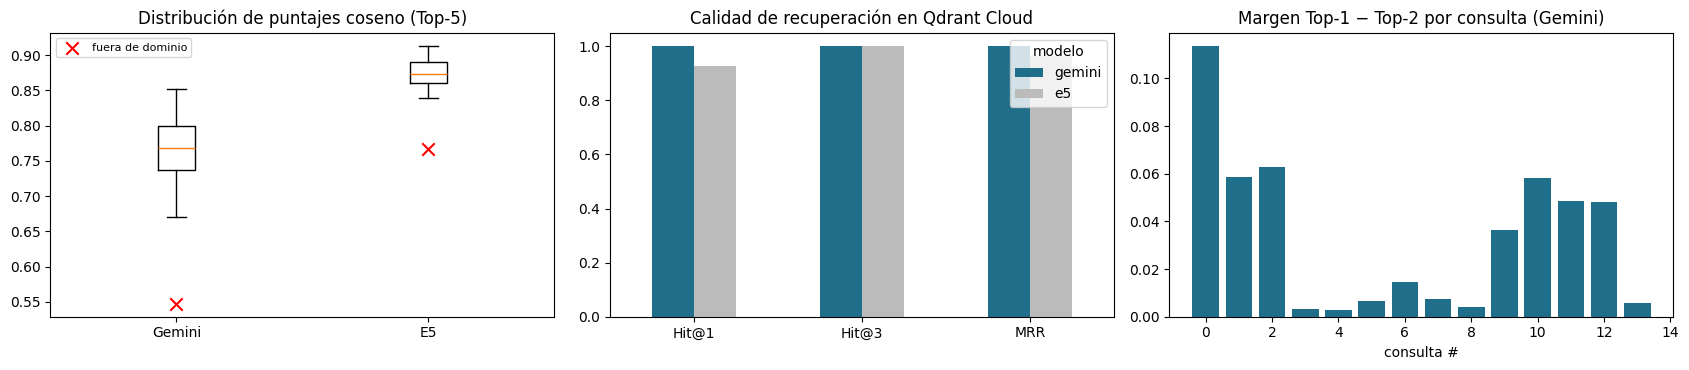

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].boxplot([np.concatenate(det_g.scores.values), np.concatenate(det_e.scores.values)])
ax[0].set_xticks([1, 2], ["Gemini", "E5"])
ax[0].scatter([1, 2], [m_g["score_fuera_dominio"], m_e["score_fuera_dominio"]], c="red", marker="x", s=80,
              label="fuera de dominio", zorder=3)
ax[0].set_title("Distribución de puntajes coseno (Top-5)"); ax[0].legend(fontsize=8)
METRICAS[["Hit@1", "Hit@3", "MRR"]].T.plot.bar(ax=ax[1], rot=0, color=["#1f6f8b", "#bbbbbb"])
ax[1].set_ylim(0, 1.05); ax[1].set_title("Calidad de recuperación en Qdrant Cloud")
ax[2].bar(range(len(det_g)), det_g.margen_top1_top2, color="#1f6f8b")
ax[2].set_title("Margen Top-1 − Top-2 por consulta (Gemini)"); ax[2].set_xlabel("consulta #")
plt.tight_layout(); plt.savefig(DIR_RES / "fig_validacion.png", dpi=200); plt.show()

**Cómo leer los puntajes.** El valor absoluto del coseno **no es comparable entre modelos**. E5 produce puntajes comprimidos en un rango alto (típicamente 0,75–0,90 incluso para textos poco relacionados), mientras que Gemini usa una escala más amplia. Por eso la comparación se hace con métricas de ranking (Hit@k, MRR) y con la **separación normalizada** entre consultas del dominio y fuera de él (`separacion_z`). El umbral de relevancia que propone la celda siguiente sirve para que el RAG responda "no encontré información" en vez de inventar cuando la mejor coincidencia es débil.

In [42]:
UMBRALES = {}
for nombre, m in (("gemini", m_g), ("e5", m_e)):
    UMBRALES[nombre] = round((m["score_top1_min"] + m["score_fuera_dominio"]) / 2, 3)
    print(f"{nombre:>6}: Top-1 mínimo en dominio = {m['score_top1_min']:.3f} · fuera de dominio = "
          f"{m['score_fuera_dominio']:.3f} → umbral sugerido = {UMBRALES[nombre]}")

ganador = METRICAS["MRR"].idxmax()
display(Markdown(
    f"**Resultado.** Con {len(CHUNKS)} fragmentos indexados en Qdrant Cloud, `{ganador}` obtuvo el MRR más alto "
    f"({METRICAS.loc[ganador, 'MRR']:.3f}). Gemini: Hit@1 = {m_g['Hit@1']:.2f}, Hit@3 = {m_g['Hit@3']:.2f}, "
    f"coseno Top-1 medio = {m_g['score_top1_medio']:.3f}. E5: Hit@1 = {m_e['Hit@1']:.2f}, Hit@3 = {m_e['Hit@3']:.2f}. "
    f"Latencia mediana de búsqueda en Qdrant: {m_g['lat_qdrant_ms']:.0f} ms."))

gemini: Top-1 mínimo en dominio = 0.743 · fuera de dominio = 0.547 → umbral sugerido = 0.645
    e5: Top-1 mínimo en dominio = 0.864 · fuera de dominio = 0.767 → umbral sugerido = 0.815


**Resultado.** Con 610 fragmentos indexados en Qdrant Cloud, `gemini` obtuvo el MRR más alto (1.000). Gemini: Hit@1 = 1.00, Hit@3 = 1.00, coseno Top-1 medio = 0.805. E5: Hit@1 = 0.93, Hit@3 = 1.00. Latencia mediana de búsqueda en Qdrant: 221 ms.

## 9. Del Top-k al sistema RAG

La salida de esta ACA es el contexto que recibirá el modelo generativo. `construir_contexto` aplica el umbral, ordena los fragmentos, agrega la cita (documento y página) y la evidencia del dataset asociada, y arma el *prompt* aumentado.

In [43]:
def construir_contexto(pregunta, k=TOP_K, modelo="gemini"):
    res, _, _ = buscar(pregunta, k=k, modelo=modelo, mostrar=False)
    utiles = [p for p in res if p.score >= UMBRALES[modelo]]
    if not utiles:
        return None, "No se encontró información suficientemente relacionada en la base de conocimiento."
    bloques = []
    for i, p in enumerate(utiles, 1):
        c = p.payload
        cita = f"{c['titulo']} ({c['entidad']}, {c['anio']})" + (f", p. {c['pagina']}" if c["pagina"] else "")
        evid = f"\nEvidencia del dataset: {'; '.join(c['evidencia_dataset'])}" if c["evidencia_dataset"] else ""
        bloques.append(f"[{i}] {cita} · similitud {p.score:.3f}\n{c['texto']}{evid}")
    contexto = "\n\n".join(bloques)
    prompt = ("Eres un asistente de consulta académica y permanencia estudiantil. Responde en español usando "
              "ÚNICAMENTE el contexto y cita las fuentes con [n]. Si el contexto no alcanza, dilo.\n\n"
              f"CONTEXTO:\n{contexto}\n\nPREGUNTA: {pregunta}")
    return utiles, prompt

_, prompt = construir_contexto("Tengo deudas con la universidad y estoy pensando en retirarme, ¿qué opciones tengo?")
print(prompt[:2500])
print("\n— Consulta fuera de dominio —")
print(construir_contexto(FUERA_DE_DOMINIO[0])[1][:300])

Eres un asistente de consulta académica y permanencia estudiantil. Responde en español usando ÚNICAMENTE el contexto y cita las fuentes con [n]. Si el contexto no alcanza, dilo.

CONTEXTO:
[1] Reglamento Estudiantil CUN (Acuerdo 002 de 2011 del Consejo Directivo) (Corporación Unificada Nacional de Educación Superior (CUN), 2011), p. 7 · similitud 0.712
Artículo 16. RETIRO DEL ESTUDIANTE (MODIFICADO POR EL ACUERDO No 0 2 DE 2016 
DEL CONSEJO DIRECTIVO): Es la cancelación voluntaria de la ma trícula por parte del 
estudiante correspondiente al periodo académico en el cual se matriculó. Cuando ocurra esta 
circunstancia el estudiante deberá informar ante la instancia de atención al estudiante fijada por 
la Institución, manifestando las motivaciones de la misma. 
PARÁGRAFO PRIMERO: La solicitud de retiro deberá formularse ante la instancia de atención 
al estudiante, dentro de los primeros quince (15) días calendario de iniciado el correspondiente 
periodo académico, al efecto, la Vicerre

## 10. Exportación de resultados

Se guardan las métricas, el detalle por consulta y la configuración en `resultados/`, para el póster y el repositorio.

In [44]:
CONSULTAS_DEMO = ["¿Qué pasa si pierdo la misma asignatura por tercera vez?",
                  "¿Qué estrategias recomienda el Ministerio para apoyar a estudiantes con dificultades económicas?",
                  "¿Los estudiantes con deudas con la institución abandonan más sus estudios?"]
demo = []
for q in CONSULTAS_DEMO:
    res, _, lat = buscar(q, k=3, mostrar=False)
    demo.append({"consulta": q, "latencia": lat,
                 "top3": [{"score": round(p.score, 4), "fuente": p.payload["fuente_id"], "pagina": p.payload["pagina"],
                           "texto": p.payload["texto"][:300]} for p in res]})

resumen_final = {
    "coleccion": COLECCION, "proveedor": "Qdrant Cloud (free tier)", "distancia": "coseno",
    "modelo_principal": GEMINI_EMBED_MODEL, "dim_principal": DIM_GEMINI, "modelo_base": MODELO_E5, "dim_base": DIM_E5,
    "chunk_size": CHUNK_SIZE, "chunk_overlap": int(CHUNK_SIZE * SOLAPAMIENTO_REL), "fragmentos": len(CHUNKS),
    "fragmentos_por_fuente": pd.DataFrame(CHUNKS).fuente_id.value_counts().to_dict(),
    "paginas_por_documento": {d["fuente_id"]: d["n_paginas_pdf"] for d in DOCUMENTOS},
    "dataset": {"origen": ORIGEN_DATASET, "registros": int(len(df)), "desercion_global_pct": float(GLOBAL.pct_desercion[0])},
    "espacio_estimado_mb": round(estimado_mb, 2), "uso_gemini": USO_GEMINI,
    "experimento_chunking": EXPERIMENTO.to_dict(orient="records"),
    "metricas": METRICAS.reset_index().to_dict(orient="records"), "umbrales": UMBRALES, "consultas_demo": demo,
}
(DIR_RES / "resumen_aca1.json").write_text(json.dumps(resumen_final, ensure_ascii=False, indent=2, default=float))
pd.concat([det_g, det_e]).drop(columns="scores").to_csv(DIR_RES / "validacion_detalle.csv", index=False)
print("Archivos generados:", sorted(p.name for p in DIR_RES.iterdir()))

Archivos generados: ['fig_chunking.png', 'fig_desercion_factores.png', 'fig_topk_ejemplo.png', 'fig_validacion.png', 'resumen_aca1.json', 'validacion_detalle.csv']


## 11. Conclusiones

- **La arquitectura responde la pregunta orientadora con costo cero.** Qdrant Cloud (free tier), la API de Gemini en su capa gratuita y E5 local bastan para indexar el corpus completo; el espacio ocupado es una fracción mínima del gigabyte disponible y la caché evita volver a pagar cuota en cada ejecución.
- **El tamaño de fragmento se decidió con datos, no por costumbre.** Las tres configuraciones se compararon con el mismo conjunto de consultas antes de enviar nada a la nube. Ganó 1.500 caracteres (MRR 0,964, frente a 0,946 con 1.000 y 0,943 con 500): en la guía del MEN cada estrategia ocupa varios párrafos y un fragmento más amplio la conserva completa, sin pasar del límite de 512 tokens de E5.
- **Integrar el dataset como metadatos y fichas cambia el tipo de respuesta posible.** Una pregunta como "¿las deudas aumentan la deserción?" recupera a la vez la norma (qué dice el reglamento sobre pagos y paz y salvo), la orientación del MEN (qué estrategias de apoyo financiero existen) y la cifra observada en 4.424 estudiantes.
- **Los puntajes coseno deben leerse con cuidado.** No son probabilidades ni son comparables entre modelos; por eso la evaluación usa métricas de ranking y un umbral calibrado con consultas fuera de dominio, que el RAG usará para abstenerse cuando no tenga evidencia.
- **Limitaciones y siguiente paso (ACA 2).** El dataset describe una institución portuguesa, así que sus cifras se usan como evidencia de referencia y no como diagnóstico de la población colombiana. El conjunto de validación es pequeño (14 consultas) y debería crecer con preguntas reales de estudiantes. Queda pendiente conectar el contexto recuperado a un LLM generativo, probar *reranking* y búsqueda híbrida (densa + BM25) y desplegar la consulta como servicio.

## Referencias (APA 7)

Google. (2026). *Embeddings* [Documentación de la API de Gemini]. Google AI for Developers. https://ai.google.dev/gemini-api/docs/embeddings

Corporación Unificada Nacional de Educación Superior. (2011). *Reglamento estudiantil* (Acuerdo 002 de 2011 del Consejo Directivo). https://cdigital.cun.edu.co/pluginfile.php/364670/course/summary/Reglamento%20Estudiantil.pdf

Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474. https://arxiv.org/abs/2005.11401

Ministerio de Educación Nacional. (2015). *Guía para la implementación del modelo de gestión de permanencia y graduación estudiantil en instituciones de educación superior*. https://www.mineducacion.gov.co/1780/articles-356272_recurso.pdf

Ministerio de Educación Nacional. (2016). *Lineamientos de política de bienestar para instituciones de educación superior*. https://www.mineducacion.gov.co/1780/articles-360314_recurso.pdf

Qdrant Solutions GmbH. (2026). *Qdrant documentation*. https://qdrant.tech/documentation/

Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), 146. https://doi.org/10.3390/data7110146

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict students' dropout and academic success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. En *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing* (pp. 3982–3992). https://arxiv.org/abs/1908.10084

Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (2024). *Multilingual E5 text embeddings: A technical report* (arXiv:2402.05672). arXiv. https://arxiv.org/abs/2402.05672